# Exercise 4 - Text Pre-processing

**Anggota Kelompok:**
1. M. Furqon Lutfi Septriandri (25031554192)
2. Akram Ali Fi Natarik (25031554212)

**Data yang dipakai (hasil scraping Exercise 3):**
1. **HTTP scraping** : artikel detik.com *"50 Kata-kata Bijak Hari Ini"* (Bahasa Indonesia)
2. **API scraping** : REST API JSONPlaceholder `/posts` (100 post)

**Alur pre-processing** (mengikuti materi Chapter 4):
remove HTML 
- remove hashtag 
- lower casing 
- remove URL/email 
- remove punctuation 
- remove emoji 
- stemming 
- remove stopwords

## 0. Install & Import Library

In [29]:
%pip install nltk demoji wordcloud pandas requests beautifulsoup4 matplotlib
%pip install Levenshtein
%pip install --upgrade git+https://github.com/ariaghora/mpstemmer.git


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
  Cloning https://github.com/ariaghora/mpstemmer.git to C:\Users\sept\AppData\Local\Temp\pip-req-build-2hph16u5
  Resolved https://github.com/ariaghora/mpstemmer.git to commit 25a5fd923af163a7eac3a5ec976984156ca8fa8b
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Note: you may need to restart the kernel to use updated packages.


  Running command git clone --filter=blob:none --quiet https://github.com/ariaghora/mpstemmer.git 'C:\Users\sept\AppData\Local\Temp\pip-req-build-2hph16u5'


In [30]:
import warnings
warnings.filterwarnings(action='ignore')

import re, json
import requests
import pandas as pd
import demoji
import nltk
from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from mpstemmer import MPStemmer
from wordcloud import WordCloud
import matplotlib.pyplot as plt

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sept\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## 1. Fungsi Pre-processing

In [31]:
def remove_html(text):
    html_pattern = re.compile('<.*?>')
    return html_pattern.sub(r'', str(text))

def remove_hashtag(text):
    return re.sub(r'#\w+', '', str(text))

def remove_rls(text):
    text = re.sub(r'https?://\S+', '', str(text))   
    text = re.sub(r'http\S+', '', text)              
    text = re.sub(r'www\S+', '', text)               
    text = re.sub(r'\S+@\S+', '', text)              
    return text

def remove_punctuation_list(text):
    text = re.sub(r'(:\)|:-\)|:D|:-D|;\)|;-\))', '', text)
    text = re.sub(r'(:\(|:-\()', '', text)
    text = re.sub(r'(:v|:-v)', '', text)
    text = re.sub(r'[!"#$%&\'()*+,\-./:;<=>?@\[\]^_`{|}~]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def remove_emoji(text):
    return demoji.replace(text, repl="")

def remove_stopwords(text, sw):
    return " ".join([w for w in str(text).split() if w not in sw])

In [32]:
def remove_noise_detik(text):
    text = re.sub(r'scroll to continue with content', '', str(text), flags=re.I)
    text = re.sub(r'^\s*\d+\.\s*', '', text)   
    return text.strip()

stemmer = MPStemmer()
sw_id = set(stopwords.words('indonesian'))

## 2. Dataset 1 - HTTP Scraping (detik.com, Bahasa Indonesia)

In [33]:
url = "https://www.detik.com/sumbagsel/berita/d-8371084/50-kata-kata-bijak-hari-ini-terbaru-seru-dan-penuh-arti"
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

try:
    page = requests.get(url, headers=headers, timeout=15)
    page.raise_for_status()
    soup = BeautifulSoup(page.text, "html.parser")
    konten_div = soup.find("div", class_="detail__body-text")
    paragraf = konten_div.find_all(["p", "li"])
    hasil_teks = [p.get_text(strip=True) for p in paragraf if p.get_text(strip=True)]
    df_detik = pd.DataFrame({"No": range(1, len(hasil_teks) + 1), "text": hasil_teks})
    print("Data diambil dari website:", len(df_detik), "baris")
except Exception as e:
    print("Scraping gagal, pakai file CSV hasil Exercise 3 ->", e)
    df_detik = pd.read_csv("hasil_scraping_detik.csv").rename(columns={"Isi Paragraf": "text"})

df_detik.to_csv("hasil_scraping_detik.csv", index=False)
df_detik.head(12)

Data diambil dari website: 59 baris


,No,text
0,1,Kata-kata Bijak Tentang Pertumbuhan Diri
1,2,Kata-kata Bijak Tentang Kebahagiaan & Syukur
2,3,Kata-kata Bijak Tentang Perjuangan & Kegagalan
3,4,Kata-kata Bijak Tentang Hubungan Sesama Manusia
4,5,Kata-kata Bijak Prinsip Hidup Sehari-hari
5,6,Kata-kata bijak hari ini bisa menjadi motivasi...
6,7,Tujuan dari kata-kata bijak adalah memberikan ...
7,8,Berikut 50 kata-kata bijak hari ini yang bisa ...
8,9,SCROLL TO CONTINUE WITH CONTENT
9,10,"1. Hidup itu seperti bersepeda, untuk menjaga ..."


In [34]:
df_detik.info()

<class 'pandas.DataFrame'>
RangeIndex: 59 entries, 0 to 58
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   No      59 non-null     int64
 1   text    59 non-null     str  
dtypes: int64(1), str(1)
memory usage: 1.1 KB


### Word cloud sebelum pre-processing

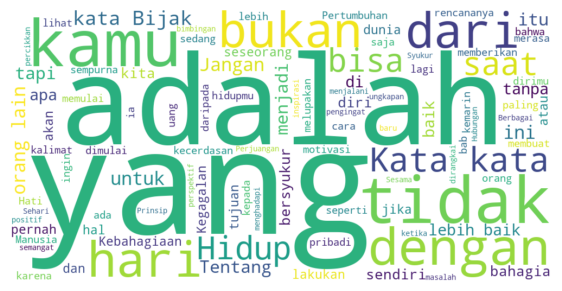

In [35]:
def show_wc(series, max_words=100):
    teks = ' '.join(series.dropna().astype(str))
    wc = WordCloud(width=1000, height=500, background_color='white', max_words=max_words).generate(teks)
    plt.figure(figsize=(7, 4)); plt.imshow(wc, interpolation='bilinear'); plt.axis('off'); plt.show()

show_wc(df_detik['text'])

### Proses pre-processing tiap tahap

In [36]:
df_detik['rm_html'] = df_detik['text'].apply(remove_html)
df_detik[['text', 'rm_html']].head()

,text,rm_html
0,Kata-kata Bijak Tentang Pertumbuhan Diri,Kata-kata Bijak Tentang Pertumbuhan Diri
1,Kata-kata Bijak Tentang Kebahagiaan & Syukur,Kata-kata Bijak Tentang Kebahagiaan & Syukur
2,Kata-kata Bijak Tentang Perjuangan & Kegagalan,Kata-kata Bijak Tentang Perjuangan & Kegagalan
3,Kata-kata Bijak Tentang Hubungan Sesama Manusia,Kata-kata Bijak Tentang Hubungan Sesama Manusia
4,Kata-kata Bijak Prinsip Hidup Sehari-hari,Kata-kata Bijak Prinsip Hidup Sehari-hari


In [37]:
df_detik['rm_hashtag'] = df_detik['rm_html'].apply(remove_hashtag)
df_detik[['rm_html', 'rm_hashtag']].head()

,rm_html,rm_hashtag
0,Kata-kata Bijak Tentang Pertumbuhan Diri,Kata-kata Bijak Tentang Pertumbuhan Diri
1,Kata-kata Bijak Tentang Kebahagiaan & Syukur,Kata-kata Bijak Tentang Kebahagiaan & Syukur
2,Kata-kata Bijak Tentang Perjuangan & Kegagalan,Kata-kata Bijak Tentang Perjuangan & Kegagalan
3,Kata-kata Bijak Tentang Hubungan Sesama Manusia,Kata-kata Bijak Tentang Hubungan Sesama Manusia
4,Kata-kata Bijak Prinsip Hidup Sehari-hari,Kata-kata Bijak Prinsip Hidup Sehari-hari


In [38]:
df_detik['lower_case'] = df_detik['rm_hashtag'].str.lower()
df_detik[['rm_hashtag', 'lower_case']].head()

,rm_hashtag,lower_case
0,Kata-kata Bijak Tentang Pertumbuhan Diri,kata-kata bijak tentang pertumbuhan diri
1,Kata-kata Bijak Tentang Kebahagiaan & Syukur,kata-kata bijak tentang kebahagiaan & syukur
2,Kata-kata Bijak Tentang Perjuangan & Kegagalan,kata-kata bijak tentang perjuangan & kegagalan
3,Kata-kata Bijak Tentang Hubungan Sesama Manusia,kata-kata bijak tentang hubungan sesama manusia
4,Kata-kata Bijak Prinsip Hidup Sehari-hari,kata-kata bijak prinsip hidup sehari-hari


In [39]:
df_detik['rm_url'] = df_detik['lower_case'].apply(remove_rls)
df_detik[['lower_case', 'rm_url']].head()

,lower_case,rm_url
0,kata-kata bijak tentang pertumbuhan diri,kata-kata bijak tentang pertumbuhan diri
1,kata-kata bijak tentang kebahagiaan & syukur,kata-kata bijak tentang kebahagiaan & syukur
2,kata-kata bijak tentang perjuangan & kegagalan,kata-kata bijak tentang perjuangan & kegagalan
3,kata-kata bijak tentang hubungan sesama manusia,kata-kata bijak tentang hubungan sesama manusia
4,kata-kata bijak prinsip hidup sehari-hari,kata-kata bijak prinsip hidup sehari-hari


In [40]:
df_detik['rm_noise'] = df_detik['rm_url'].apply(remove_noise_detik)
df_detik[['rm_url', 'rm_noise']].iloc[6:14]

,rm_url,rm_noise
6,tujuan dari kata-kata bijak adalah memberikan ...,tujuan dari kata-kata bijak adalah memberikan ...
7,berikut 50 kata-kata bijak hari ini yang bisa ...,berikut 50 kata-kata bijak hari ini yang bisa ...
8,scroll to continue with content,
9,"1. hidup itu seperti bersepeda, untuk menjaga ...","hidup itu seperti bersepeda, untuk menjaga kes..."
10,2. jangan bandingkan bab pertama hidupmu denga...,jangan bandingkan bab pertama hidupmu dengan b...
11,3. kesalahan adalah bukti bahwa kamu sedang me...,kesalahan adalah bukti bahwa kamu sedang mencoba.
12,4. karakter seseorang terlihat dari apa yang i...,karakter seseorang terlihat dari apa yang ia l...
13,5. pertumbuhan dimulai di ujung zona nyamanmu.,pertumbuhan dimulai di ujung zona nyamanmu.


In [41]:
df_detik['rm_punc'] = df_detik['rm_noise'].apply(remove_punctuation_list)
df_detik[['rm_noise', 'rm_punc']].iloc[6:14]

,rm_noise,rm_punc
6,tujuan dari kata-kata bijak adalah memberikan ...,tujuan dari kata kata bijak adalah memberikan ...
7,berikut 50 kata-kata bijak hari ini yang bisa ...,berikut 50 kata kata bijak hari ini yang bisa ...
8,,
9,"hidup itu seperti bersepeda, untuk menjaga kes...",hidup itu seperti bersepeda untuk menjaga kese...
10,jangan bandingkan bab pertama hidupmu dengan b...,jangan bandingkan bab pertama hidupmu dengan b...
11,kesalahan adalah bukti bahwa kamu sedang mencoba.,kesalahan adalah bukti bahwa kamu sedang mencoba
12,karakter seseorang terlihat dari apa yang ia l...,karakter seseorang terlihat dari apa yang ia l...
13,pertumbuhan dimulai di ujung zona nyamanmu.,pertumbuhan dimulai di ujung zona nyamanmu


In [42]:
df_detik['rm_emoji'] = df_detik['rm_punc'].apply(remove_emoji)
df_detik[['rm_punc', 'rm_emoji']].head()

,rm_punc,rm_emoji
0,kata kata bijak tentang pertumbuhan diri,kata kata bijak tentang pertumbuhan diri
1,kata kata bijak tentang kebahagiaan syukur,kata kata bijak tentang kebahagiaan syukur
2,kata kata bijak tentang perjuangan kegagalan,kata kata bijak tentang perjuangan kegagalan
3,kata kata bijak tentang hubungan sesama manusia,kata kata bijak tentang hubungan sesama manusia
4,kata kata bijak prinsip hidup sehari hari,kata kata bijak prinsip hidup sehari hari


In [43]:
df_detik['stem'] = df_detik['rm_emoji'].apply(lambda x: stemmer.stem_kalimat(x) if isinstance(x, str) else '')
df_detik[['rm_emoji', 'stem']].head(15)

,rm_emoji,stem
0,kata kata bijak tentang pertumbuhan diri,kata kata bijak tentang tumbuh diri
1,kata kata bijak tentang kebahagiaan syukur,kata kata bijak tentang bahagia syukur
2,kata kata bijak tentang perjuangan kegagalan,kata kata bijak tentang juang gagal
3,kata kata bijak tentang hubungan sesama manusia,kata kata bijak tentang hubung sama manusia
4,kata kata bijak prinsip hidup sehari hari,kata kata bijak prinsip hidup sehari hari
5,kata kata bijak hari ini bisa menjadi motivasi...,kata kata bijak hari ini bisa jadi motivasi da...
6,tujuan dari kata kata bijak adalah memberikan ...,tuju dari kata kata bijak adalah beri motivasi...
7,berikut 50 kata kata bijak hari ini yang bisa ...,ikut 50 kata kata bijak hari ini yang bisa jad...
8,,
9,hidup itu seperti bersepeda untuk menjaga kese...,hidup itu seperti sepeda untuk jaga seimbang k...


In [44]:
df_detik['rm_stopwords'] = df_detik['stem'].apply(lambda x: remove_stopwords(x, sw_id))
df_detik[['stem', 'rm_stopwords']].head(15)

,stem,rm_stopwords
0,kata kata bijak tentang tumbuh diri,bijak tumbuh
1,kata kata bijak tentang bahagia syukur,bijak bahagia syukur
2,kata kata bijak tentang juang gagal,bijak juang gagal
3,kata kata bijak tentang hubung sama manusia,bijak hubung manusia
4,kata kata bijak prinsip hidup sehari hari,bijak prinsip hidup sehari
5,kata kata bijak hari ini bisa jadi motivasi da...,bijak motivasi hidup rangkai kalimat percik se...
6,tuju dari kata kata bijak adalah beri motivasi...,tuju bijak motivasi bimbing inspirasi perspekt...
7,ikut 50 kata kata bijak hari ini yang bisa jad...,50 bijak caption media sosial ayo pilih sesuai...
8,,
9,hidup itu seperti sepeda untuk jaga seimbang k...,hidup sepeda jaga seimbang gerak


In [45]:
df_detik.rename(columns={'rm_stopwords': 'prepro'}, inplace=True)
print("Baris kosong:", (df_detik['prepro'].str.strip() == '').sum())
df_detik = df_detik[df_detik['prepro'].str.strip() != ''].reset_index(drop=True)
df_detik['tokens'] = df_detik['prepro'].str.split()
df_detik[['text', 'prepro', 'tokens']].head(10)

Baris kosong: 1


,text,prepro,tokens
0,Kata-kata Bijak Tentang Pertumbuhan Diri,bijak tumbuh,"[bijak, tumbuh]"
1,Kata-kata Bijak Tentang Kebahagiaan & Syukur,bijak bahagia syukur,"[bijak, bahagia, syukur]"
2,Kata-kata Bijak Tentang Perjuangan & Kegagalan,bijak juang gagal,"[bijak, juang, gagal]"
3,Kata-kata Bijak Tentang Hubungan Sesama Manusia,bijak hubung manusia,"[bijak, hubung, manusia]"
4,Kata-kata Bijak Prinsip Hidup Sehari-hari,bijak prinsip hidup sehari,"[bijak, prinsip, hidup, sehari]"
5,Kata-kata bijak hari ini bisa menjadi motivasi...,bijak motivasi hidup rangkai kalimat percik se...,"[bijak, motivasi, hidup, rangkai, kalimat, per..."
6,Tujuan dari kata-kata bijak adalah memberikan ...,tuju bijak motivasi bimbing inspirasi perspekt...,"[tuju, bijak, motivasi, bimbing, inspirasi, pe..."
7,Berikut 50 kata-kata bijak hari ini yang bisa ...,50 bijak caption media sosial ayo pilih sesuai...,"[50, bijak, caption, media, sosial, ayo, pilih..."
8,"1. Hidup itu seperti bersepeda, untuk menjaga ...",hidup sepeda jaga seimbang gerak,"[hidup, sepeda, jaga, seimbang, gerak]"
9,2. Jangan bandingkan bab pertama hidupmu denga...,banding bab hidup bab puluh orang,"[banding, bab, hidup, bab, puluh, orang]"


### Word cloud setelah pre-processing

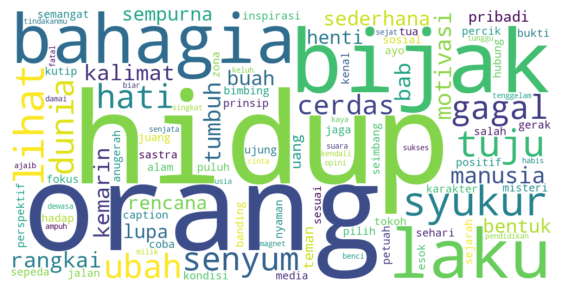

In [46]:
show_wc(df_detik['prepro'])

In [47]:
df_detik[['No', 'text', 'prepro']].to_csv('detik_preprocessed.csv', index=False)

## 3. Dataset 2 - API Scraping (JSONPlaceholder `/posts`)

In [48]:
try:
    data = requests.get("https://jsonplaceholder.typicode.com/posts", timeout=15).json()
    print("Data diambil dari API:", len(data), "post")
except Exception as e:
    print("Request gagal, baca file JSON hasil Exercise 3 ->", e)
    with open("hasil scraping posts.json", "r") as f:
        data = json.load(f)

df_api = pd.DataFrame(data)
df_api['text'] = df_api['title'] + ' ' + df_api['body']
df_api[['id', 'text']].head()

Data diambil dari API: 100 post


,id,text
0,1,sunt aut facere repellat provident occaecati e...
1,2,qui est esse est rerum tempore vitae\nsequi si...
2,3,ea molestias quasi exercitationem repellat qui...
3,4,eum et est occaecati ullam et saepe reiciendis...
4,5,nesciunt quas odio repudiandae veniam quaerat ...


In [49]:
df_api['rm_html']    = df_api['text'].apply(remove_html)
df_api['rm_hashtag'] = df_api['rm_html'].apply(remove_hashtag)
df_api['lower_case'] = df_api['rm_hashtag'].str.lower()
df_api['rm_url']     = df_api['lower_case'].apply(remove_rls)
df_api['rm_punc']    = df_api['rm_url'].apply(remove_punctuation_list)   
df_api['prepro']     = df_api['rm_punc'].apply(remove_emoji)
df_api['tokens']     = df_api['prepro'].str.split()

df_api[['text', 'prepro']].head()

,text,prepro
0,sunt aut facere repellat provident occaecati e...,sunt aut facere repellat provident occaecati e...
1,qui est esse est rerum tempore vitae\nsequi si...,qui est esse est rerum tempore vitae sequi sin...
2,ea molestias quasi exercitationem repellat qui...,ea molestias quasi exercitationem repellat qui...
3,eum et est occaecati ullam et saepe reiciendis...,eum et est occaecati ullam et saepe reiciendis...
4,nesciunt quas odio repudiandae veniam quaerat ...,nesciunt quas odio repudiandae veniam quaerat ...


Rata-rata jumlah token : 29.98
Jumlah kata unik       : 182


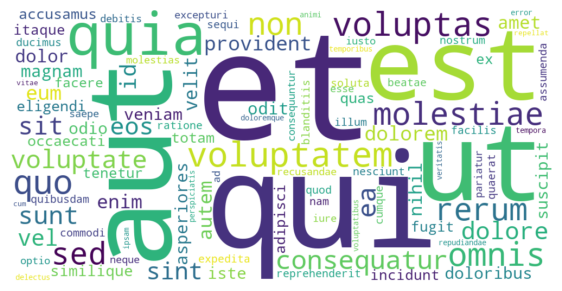

In [50]:
print("Rata-rata jumlah token :", df_api['tokens'].apply(len).mean())
print("Jumlah kata unik       :", len(set(w for t in df_api['tokens'] for w in t)))
show_wc(df_api['prepro'])

In [51]:
df_api[['userId', 'id', 'text', 'prepro']].to_csv('jsonplaceholder_preprocessed.csv', index=False)

## 4. Ringkasan

In [52]:
print("detik          :", len(df_detik), "dokumen | rata-rata token sebelum:",
      round(df_detik['text'].str.split().apply(len).mean(), 1), "-> sesudah:",
      round(df_detik['tokens'].apply(len).mean(), 1))
print("JSONPlaceholder:", len(df_api), "dokumen | rata-rata token sebelum:",
      round(df_api['text'].str.split().apply(len).mean(), 1), "-> sesudah:",
      round(df_api['tokens'].apply(len).mean(), 1))

detik          : 58 dokumen | rata-rata token sebelum: 10.8 -> sesudah: 4.2
JSONPlaceholder: 100 dokumen | rata-rata token sebelum: 30.0 -> sesudah: 30.0
